In [2]:
# imports
import simpy
import numpy as np
import sys
import pandas as pd
import os
from IPython.display import Image
from tqdm import tqdm
import matplotlib.pyplot as plt
import time





### Discrete event simulation (DES) is a type of simulation modeling that focuses on modeling the operation of systems as a sequence of discrete events in time. In a discrete event simulation, the system evolves over time, and events occur at distinct points in time, causing the system to change its state.

### Key features of discrete event simulation include:

## Events:
Events represent specific points in time when something happens in the system. These events could be arrivals, departures, failures, repairs, or any other occurrences that affect the system.

## Time: 
### Time is modeled as a series of discrete points, typically progressing in chronological order. The simulation progresses from one event to the next, with time advancing only when an event occurs.

## State Changes: 
### The system undergoes changes in state as events occur. The state of the system at any given point is determined by the occurrence and order of events.

## Queues:
### Queues are often a fundamental component of discrete event simulations, representing the accumulation of entities (e.g., customers, tasks, jobs) waiting for service.





# Python Generator

<div dir="rtl">

### בpython יש דבר שנקרא generator. זה כמו פונקציה רק במקום שמחזירים ערך עם return מחזירים עם משהו שנקרא yield. בואו נראה דוגמא:

In [2]:
def keep_count_generator():
    
    count = 0
    
    while True:
        
        count += 1
        
        ## yield instead of return
        yield count
        
my_generator = keep_count_generator() 


## The yield function remember where we left off
print(next(my_generator))
print(next(my_generator))
print(next(my_generator))
print(next(my_generator))
print(next(my_generator))



1
2
3
4
5


In [15]:
def keep_count_conventional():
    
    count = 0
    
    for ind in range(5):
        
        count += 1
        
        return count

print(keep_count_conventional())
print(keep_count_conventional())
print(keep_count_conventional())
print(keep_count_conventional())
print(keep_count_conventional())

1
1
1
1
1


<div dir="rtl">

#### כלומר ברגע שמחזירים בעזרת yield הפונקציה זוכרת איפה היא הייתה בפעם הקודמת
    
#### כעת, נכיר מושגים בסיסיים בsimpy ונבנה מערכת פשוטה

### מערכת תורים שמדמה חדר מיון - כאשר בצורה הדרגתית נוסיף סיבוכיות
    
### תחילה נסמלץ תור $M/M/1$
    
### במערכת הזאת מטופלים מגיעים לאחות והולכים

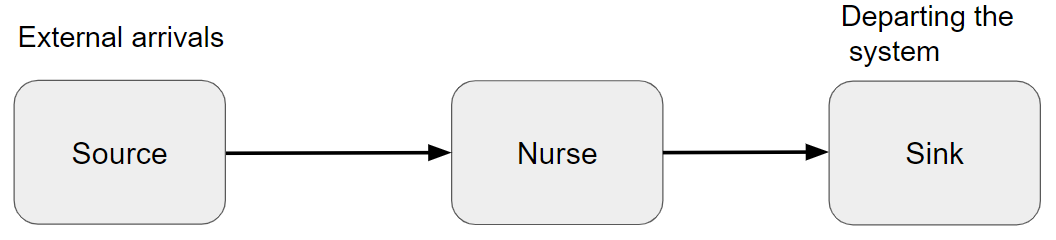

In [4]:
Image('../Images/nurse.png', width=720)

In [6]:
## Model input
mu = 2
lamda = 1
end_time = 25

In [7]:
#########################################################
#################  Initiate system ###################### 
#########################################################        

# Defining a simpy envirment
env = simpy.Environment()
# Attaching a server to a simpy envirment
nurse = simpy.Resource(env, capacity=1)

### Environment: simpy.Environment()

### Resource: simpy.Resource(env, capacity=capacity)

<div dir="rtl">


## בsimpy אנחנו צריכים להגדיר 2 בלוקים: אחד עבור תהליך הגעה של של צרכנים אל המערכת והשני עבור השירות, שם מתנהל התור



In [9]:
#########################################################
###################  Arrival block ###################### 
#########################################################
                
def customer_arrivals(env):
    
    id_customer = 0
    
    while True:
        
        id_customer += 1
        
        # Timeout means the time span bewteen two arrivals
        yield env.timeout(np.random.exponential(1/lamda))
        
        print('Customer {} arrived at time: {}' .format(id_customer, env.now))

        env.process(service(env, id_customer))

In [10]:
# Initializing an arrival process
env.process(customer_arrivals(env))

<Process(customer_arrivals) object at 0x292db716ed0>

<div dir="rtl">

### פה אנחנו מגדירים איזה תהליך מתחיל את הסימולציה - באופן טבעי זה יהיה תהליך הגעה כי זה המקור של הכל

<div dir="rtl">

### בלוק של השירות: בבלוק הזה עבור צרכן שמגיע נבקש שירות וכאשר השרת מתפנה נעשהtimeout שזה הזמן הצרכן לוקח מהשרת

In [11]:
#########################################################
###################  Service block ###################### 
#########################################################

def service(env, id_customer):

    ## For tracking the arrival time of customer
    arrival_time = env.now

    with nurse.request() as req:
        
        ## Requesting a server
        yield req
        print('Customer {} start service  at time: {}' .format(id_customer, env.now))
        # if server if available service will be granted.
        
        # Timeout means the time span bewteen a single service
        yield env.timeout(np.random.exponential(1/mu))
        
        print('Customer {} complete service  at time: {}' .format(id_customer, env.now))



In [12]:
# Activating the system
env.run(until=end_time)

Customer 1 arrived at time: 0.16582085486007345
Customer 1 start service  at time: 0.16582085486007345
Customer 2 arrived at time: 1.0544615955448742
Customer 1 complete service  at time: 1.41345911442642
Customer 2 start service  at time: 1.41345911442642
Customer 2 complete service  at time: 2.508621515515033
Customer 3 arrived at time: 6.0869890557574315
Customer 3 start service  at time: 6.0869890557574315
Customer 4 arrived at time: 6.125422524251172
Customer 3 complete service  at time: 6.26974144449614
Customer 4 start service  at time: 6.26974144449614
Customer 5 arrived at time: 6.408610081930651
Customer 6 arrived at time: 6.433419344250745
Customer 4 complete service  at time: 6.457219333768108
Customer 5 start service  at time: 6.457219333768108
Customer 5 complete service  at time: 6.670391303125094
Customer 6 start service  at time: 6.670391303125094
Customer 6 complete service  at time: 6.737090833328532
Customer 7 arrived at time: 7.2652156244285715
Customer 7 start ser

### All in one piece.

In [13]:
## Model input

mu = 2
lamda = 1
end_time = 25

#########################################################
###################  Arrival block ###################### 
#########################################################

def customer_arrivals(env):
    
    id_customer = 0
    
    while True:
        
        id_customer += 1
        
        # Timeout means the time span bewteen two arrivals
        yield env.timeout(np.random.exponential(1/lamda))
        
        print('Customer {} arrived  at time: {}' .format(id_customer, env.now))

        env.process(service(env, id_customer))

#########################################################
###################  Service block ###################### 
#########################################################

def service(env, id_customer):

    ## For tracking the arrival time of customer
    arrival_time = env.now

    with nurse.request() as req:
        
        ## Requesting a server
        yield req
        print('Customer {} start service  at time: {}' .format(id_customer, env.now))
        # if server if available service will be granted.
        
        # Timeout means the time span bewteen a single service
        yield env.timeout(np.random.exponential(1/mu))
        
        print('Customer {} complete service  at time: {}' .format(id_customer, env.now))



#########################################################
#################  Initiate system ###################### 
#########################################################        

# Defining a simpy envirment
env = simpy.Environment()
# Attaching a server to a simpy envirment
nurse = simpy.Resource(env, capacity=1)

# Initializing an arrival process
env.process(customer_arrivals(env))

# env.process(customer_arrivals_from_doctor(env))

# Activating the system
env.run(until=end_time)

Customer 1 arrived  at time: 0.03771523439819814
Customer 1 start service  at time: 0.03771523439819814
Customer 1 complete service  at time: 0.3953277252490876
Customer 2 arrived  at time: 1.103773935067217
Customer 2 start service  at time: 1.103773935067217
Customer 2 complete service  at time: 1.2369332098325676
Customer 3 arrived  at time: 2.3743458599148584
Customer 3 start service  at time: 2.3743458599148584
Customer 3 complete service  at time: 3.1486092202745333
Customer 4 arrived  at time: 3.2311918221437974
Customer 4 start service  at time: 3.2311918221437974
Customer 5 arrived  at time: 4.322247112647472
Customer 6 arrived  at time: 4.588094945243453
Customer 4 complete service  at time: 4.775075227927758
Customer 5 start service  at time: 4.775075227927758
Customer 5 complete service  at time: 4.961232173618112
Customer 6 start service  at time: 4.961232173618112
Customer 6 complete service  at time: 4.993047080581774
Customer 7 arrived  at time: 5.751082799347739
Custom

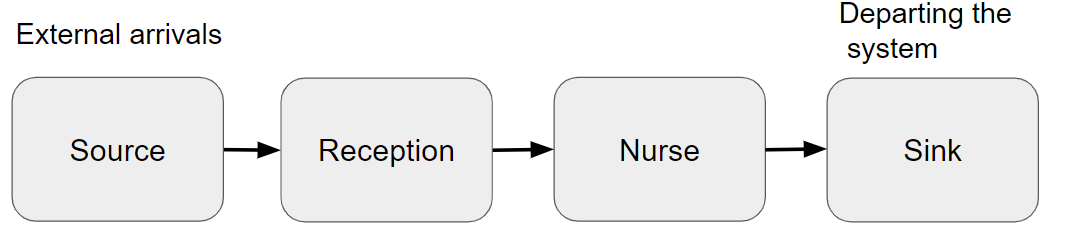

In [5]:
Image('../Images/reception_nurse.png', width=720)

<div dir="rtl">

### כעת נוסיף תחנה. תחילה מטופלים מגיעים לקבלה כדי להירשם ולאחר מכן מגיעים לאחות כפי שמתואר בתמונה. 

### בעצם צריך לעשות שני דברים:

#### 1. להוסיף בלוק שירות נוסף.
#### 2. לגרום לבלוק שירות הראשון לשלוח לבלוק שירות הבא.

    
#### נשנה את הקוד בהתאם:

In [25]:
## Model input

mu_reception = 2
mu_nurse = 1.5
lamda = 1
end_time = 25

#########################################################
###################  Arrival block ###################### 
#########################################################
                
def customer_arrivals(env):
    
    id_customer = 0
    
    while True:
        
        id_customer += 1
        
        # Timeout means the time span bewteen two arrivals
        yield env.timeout(np.random.exponential(1/lamda))
        
        print('Customer {} arrived at time: {}' .format(id_customer, env.now))

        env.process(service_reception(env, id_customer))

#########################################################
###################  Service reception block ############
#########################################################

def service_reception(env, id_customer):

    ## For tracking the arrival time of customer
    arrival_time = env.now
    
    
    with reception.request() as req:
        
        ## Requesting a server
        yield req
        print('Customer {} start reception service  at time: {}' .format(id_customer, env.now))
        # if server if available service will be granted.
        
        # Timeout means the time span bewteen a single service
        yield env.timeout(np.random.exponential(1/mu_reception))
        
        print('Customer {} complete reception service  at time: {}' .format(id_customer, env.now))

        ### Reception sends patient to nurse 
        env.process(service_nurse(env, id_customer))

        
#########################################################
###################  Service nurse block ################
#########################################################
    
def service_nurse(env, id_customer):
    
    with nurse.request() as req:
        
        ## Requesting a server
        yield req
        print('Customer {} start nurse service  at time: {}' .format(id_customer, env.now))
        # if server if available service will be granted.
        
        # Timeout means the time span bewteen a single service
        yield env.timeout(np.random.exponential(1/mu_nurse))
        
        print('Customer {} complete nurse service  at time: {}' .format(id_customer, env.now))

        ## This means the customers departs the system

#########################################################
#################  Initiate system ###################### 
#########################################################        

# Defining a simpy envirment
env = simpy.Environment()
# Attaching a server to a simpy envirment
nurse = simpy.Resource(env, capacity=1)
reception = simpy.Resource(env, capacity=1)

# Initializing an arrival process
env.process(customer_arrivals(env))

# Activating the system
env.run(until=end_time)

Customer 1 arrived at time: 0.2184701892572288
Customer 1 start reception service  at time: 0.2184701892572288
Customer 2 arrived at time: 0.3185260250422553
Customer 3 arrived at time: 1.0286471681791285
Customer 1 complete reception service  at time: 1.0765470160986383
Customer 1 start nurse service  at time: 1.0765470160986383
Customer 2 start reception service  at time: 1.0765470160986383
Customer 2 complete reception service  at time: 1.306100702370855
Customer 3 start reception service  at time: 1.306100702370855
Customer 4 arrived at time: 1.553393579308521
Customer 1 complete nurse service  at time: 1.9978548852111246
Customer 2 start nurse service  at time: 1.9978548852111246
Customer 2 complete nurse service  at time: 2.0275761334275813
Customer 3 complete reception service  at time: 2.512533441965576
Customer 3 start nurse service  at time: 2.512533441965576
Customer 4 start reception service  at time: 2.512533441965576
Customer 3 complete nurse service  at time: 2.583388666

<div dir="rtl">

## דרך נוספת לממש את זה - לעשות את כל השירות בבלוק אחד ואז בעצם יהיה לנו שלבים. 

### כלומר בשני המקרים יהיה בקשה לשרת ובשני מקרים יהיה timeout כאשר השרת ניתן לצרכן

In [26]:
## Model input

mu_reception = 2
mu_nurse = 1.5
lamda = 1
end_time = 25

#########################################################
###################  Arrival block ###################### 
#########################################################
                
def customer_arrivals(env):
    
    id_customer = 0
    
    while True:
        
        id_customer += 1
        
        # Timeout means the time span bewteen two arrivals
        yield env.timeout(np.random.exponential(1/lamda))
        
        print('Customer {} arrived at time: {}' .format(id_customer, env.now))

        env.process(service(env, id_customer))

#########################################################
###################  Service block ###################### 
#########################################################

def service(env, id_customer):

    ## For tracking the arrival time of customer
    arrival_time = env.now
    
    
    with reception.request() as req:
        
        ## Requesting a server
        yield req
        print('Customer {} start reception service  at time: {}' .format(id_customer, env.now))
        # if server if available service will be granted.
        
        # Timeout means the time span bewteen a single service
        yield env.timeout(np.random.exponential(1/mu_reception))
        
        print('Customer {} complete reception service  at time: {}' .format(id_customer, env.now))

    

    with nurse.request() as req:
        
        ## Requesting a server
        yield req
        print('Customer {} start nurse service  at time: {}' .format(id_customer, env.now))
        # if server if available service will be granted.
        
        # Timeout means the time span bewteen a single service
        yield env.timeout(np.random.exponential(1/mu_nurse))
        
        print('Customer {} complete nurse service  at time: {}' .format(id_customer, env.now))



#########################################################
#################  Initiate system ###################### 
#########################################################        

# Defining a simpy envirment
env = simpy.Environment()
# Attaching a server to a simpy envirment
nurse = simpy.Resource(env, capacity=1)
reception = simpy.Resource(env, capacity=1)

# Initializing an arrival process
env.process(customer_arrivals(env))

# Activating the system
env.run(until=end_time)

Customer 1 arrived at time: 0.23935509385962503
Customer 1 start reception service  at time: 0.23935509385962503
Customer 1 complete reception service  at time: 0.24010068456960396
Customer 1 start nurse service  at time: 0.24010068456960396
Customer 1 complete nurse service  at time: 0.4317767345210356
Customer 2 arrived at time: 1.92850129603876
Customer 2 start reception service  at time: 1.92850129603876
Customer 3 arrived at time: 2.026346597215881
Customer 4 arrived at time: 3.276905439390985
Customer 2 complete reception service  at time: 3.666501747262279
Customer 2 start nurse service  at time: 3.666501747262279
Customer 3 start reception service  at time: 3.666501747262279
Customer 3 complete reception service  at time: 3.691244054796302
Customer 4 start reception service  at time: 3.691244054796302
Customer 4 complete reception service  at time: 3.7251266598945256
Customer 5 arrived at time: 3.8532346108798694
Customer 5 start reception service  at time: 3.8532346108798694
C

<div dir="rtl">

## בואו ניקח את זה לרמה הבאה: 
    
### במערכת הזאת מטופלים מגיעים לקבלה, לכן מכן לאחות ואז האחות מחליטה אם לשלוח אותו לרופא של הACU כלומר מטופל עושה בדיקה ומשתחרר או לשלוח לרופא ED שזה במקרים חמורים יותר ובד"כ נגמרים באשפוז. 
    
#### ידוע כי 80 אחוז מהמקרים המטופל עובר ל-ACU ואילו רק ב20 מהמהמקרים לרופא ED. 
    
#### המערכת מתוארת בדרף למטה: 

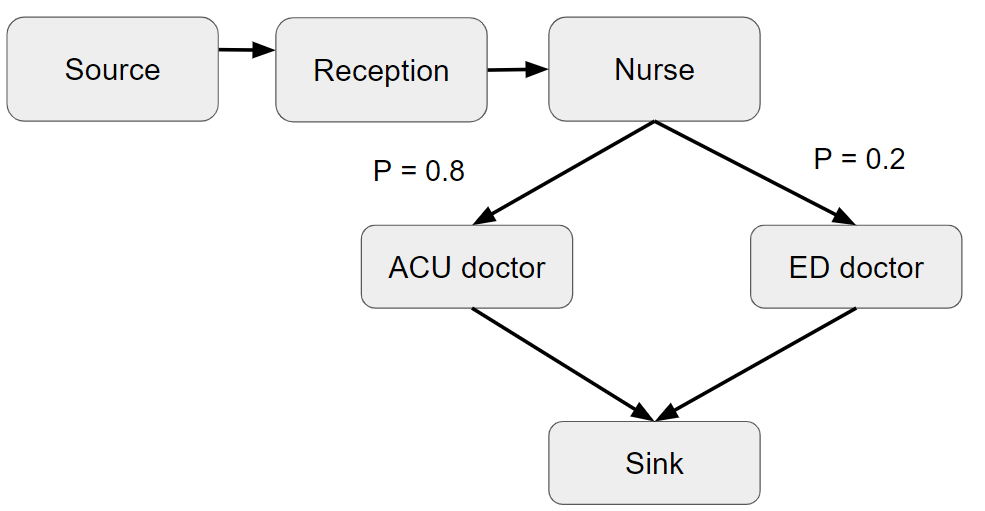

In [6]:
Image('../Images/ed_procedure.png', width=720)

In [28]:
## Model input

mu_reception = 2
mu_nurse = 1.5
mu_ed_doctor = 1.8
mu_acu_doctor = 0.9
lamda = 1
end_time = 25

#########################################################
###################  Arrival block ###################### 
#########################################################
                
def customer_arrivals(env):
    
    id_customer = 0
    
    while True:
        
        id_customer += 1
        
        # Timeout means the time span bewteen two arrivals
        yield env.timeout(np.random.exponential(1/lamda))
        
        print('Customer {} arrived at time: {}' .format(id_customer, env.now))

        env.process(service(env, id_customer))

#########################################################
###################  Service block ###################### 
#########################################################

def service(env, id_customer):

    ## For tracking the arrival time of customer
    arrival_time = env.now
    
    ################
    ## Reception ###
    ################
    
    with reception.request() as req:
        
        ## Requesting a server
        yield req
        print('Customer {} start reception service  at time: {}' .format(id_customer, env.now))
        # if server if available service will be granted.
        
        # Timeout means the time span bewteen a single service
        yield env.timeout(np.random.exponential(1/mu_reception))
        
        print('Customer {} complete reception service  at time: {}' .format(id_customer, env.now))

    ################
    ##    Nurse     ###
    ################

    with nurse.request() as req:
        
        ## Requesting a server
        yield req
        print('Customer {} start nurse service  at time: {}' .format(id_customer, env.now))
        # if server if available service will be granted.

        # Timeout means the time span bewteen a single service
        yield env.timeout(np.random.exponential(1/mu_nurse))

        print('Customer {} complete nurse service  at time: {}' .format(id_customer, env.now))
        
    ## a random number between 0 to 1
    random_decision = np.random.rand()
    
    if random_decision < 0.8:
       
        ################
        ## acu doctor ##
        ################
        
        with acu_doctor.request() as req:
        
            ## Requesting a server
            yield req
            print('Customer {} start acu_doctor service  at time: {}' .format(id_customer, env.now))
            # if server if available service will be granted.

            # Timeout means the time span bewteen a single service
            yield env.timeout(np.random.exponential(1/mu_acu_doctor))

            print('Customer {} complete acu_doctor service  at time: {}' .format(id_customer, env.now))

    else:
        
        ################
        ## ed  doctor ##
        ################
        
        with ed_doctor.request() as req:
        
            ## Requesting a server
            yield req

            print('Customer {} start ed_doctor service  at time: {}' .format(id_customer, env.now))
            # if server if available service will be granted.

            # Timeout means the time span bewteen a single service
            yield env.timeout(np.random.exponential(1/mu_ed_doctor))

            print('Customer {} complete ed_doctor service  at time: {}' .format(id_customer, env.now))



            
mu_reception = 2
mu_nurse = 1.5
mu_ed_doctor = 1.8
mu_acu_doctor = 0.9
lamda = 1
end_time = 25

#########################################################
#################  Initiate system ###################### 
#########################################################        


# Defining a simpy envirment
env = simpy.Environment()
# Attaching a server to a simpy envirment
nurse = simpy.Resource(env, capacity=1)
reception = simpy.Resource(env, capacity=1)
ed_doctor = simpy.Resource(env, capacity=1)
acu_doctor = simpy.Resource(env, capacity=1)

# Initializing an arrival process
env.process(customer_arrivals(env))

# Activating the system
env.run(until=end_time)

Customer 1 arrived at time: 1.0525616207117923
Customer 1 start reception service  at time: 1.0525616207117923
Customer 1 complete reception service  at time: 1.3888851887896774
Customer 1 start nurse service  at time: 1.3888851887896774
Customer 1 complete nurse service  at time: 1.7109761200947275
Customer 1 start acu_doctor service  at time: 1.7109761200947275
Customer 1 complete acu_doctor service  at time: 1.725669736392684
Customer 2 arrived at time: 2.2219717687155676
Customer 2 start reception service  at time: 2.2219717687155676
Customer 2 complete reception service  at time: 2.52869540001312
Customer 2 start nurse service  at time: 2.52869540001312
Customer 3 arrived at time: 2.95482849856311
Customer 3 start reception service  at time: 2.95482849856311
Customer 4 arrived at time: 3.140189120364235
Customer 3 complete reception service  at time: 3.1887035900452005
Customer 4 start reception service  at time: 3.1887035900452005
Customer 4 complete reception service  at time: 3

<div dir="rtl">


### כעת  נעשה הכל אותו דבר - רק נגדיר class שהוא ירכז את כל המידע שאנחנו צריכים
    
### זה יהיה ממש נוח בהמשך שנעשה סימולציות יותר מורכבות וכל האינפורמציה תחת אובייקט אחד

### זאת ועוד במחברת הב